<a href="https://colab.research.google.com/github/nisabulut/digital-image-processing/blob/main/2_3_goruntu_isleme.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [48]:
!sudo apt-get update && sudo apt-get install -y libopencv-dev

Get:1 https://cli.github.com/packages stable InRelease [3,917 B]
Hit:2 https://r2u.stat.illinois.edu/ubuntu noble InRelease
Hit:3 http://security.ubuntu.com/ubuntu noble-security InRelease
Hit:4 http://archive.ubuntu.com/ubuntu noble InRelease
Hit:5 https://cloud.r-project.org/bin/linux/ubuntu noble-cran40/ InRelease
Hit:6 http://archive.ubuntu.com/ubuntu noble-updates InRelease
Hit:7 https://ppa.launchpadcontent.net/deadsnakes/ppa/ubuntu noble InRelease
Hit:8 http://archive.ubuntu.com/ubuntu noble-backports InRelease
Fetched 3,917 B in 1s (4,208 B/s)
Reading package lists... Done
W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
libopencv-dev is already the newest version (4.6.0+dfsg-13.1ubuntu1).
0 upgraded, 0 newly installed, 0 to remove and 58 not up

In [49]:
%%writefile thread_kiyaslama.cpp
#include <opencv2/opencv.hpp>
#include <iostream>
#include <thread>
#include <chrono>

using namespace cv;
using namespace std;
using namespace std::chrono;

void changeBrightnessFast(Mat roi, int offset) {
    if (roi.isContinuous()) {
        uchar* data = roi.ptr<uchar>(0);
        size_t total = roi.total() * roi.channels();
        for (size_t i = 0; i < total; ++i) {
            int pixel_val = data[i] + offset;
            data[i] = static_cast<uchar>(max(0, min(255, pixel_val)));
        }
    } else {
        for (int r = 0; r < roi.rows; ++r) {
            uchar* row_ptr = roi.ptr<uchar>(r);
            for (int c = 0; c < roi.cols; ++c) {
                int pixel_val = row_ptr[c] + offset;
                row_ptr[c] = static_cast<uchar>(max(0, min(255, pixel_val)));
            }
        }
    }
}

int main(int argc, char** argv) {
    if (argc != 2) return -1;

    Mat img_gray = imread(argv[1], IMREAD_GRAYSCALE);
    if (img_gray.empty()) return -1;

    imwrite("1_orijinal.jpg", img_gray);

    bitwise_and(img_gray, 252, img_gray);
    imwrite("2_kuantize_6bit.jpg", img_gray);

    Mat img_large;
    resize(img_gray, img_large, Size(), 4.0, 4.0, INTER_LINEAR);

    Mat img_single = img_large.clone();
    Mat img_multi = img_large.clone();
    int brightness_offset = 50;

    auto start_1 = high_resolution_clock::now();
    changeBrightnessFast(img_single, brightness_offset);
    auto end_1 = high_resolution_clock::now();
    cout << "[1 THREAD] Calisma Suresi : " << duration<double, std::milli>(end_1 - start_1).count() << " ms" << endl;

    int w = img_multi.cols, h = img_multi.rows;
    int half_w = w / 2, half_h = h / 2;

    Mat q1 = img_multi(Rect(0, 0, half_w, half_h));
    Mat q2 = img_multi(Rect(half_w, 0, w - half_w, half_h));
    Mat q3 = img_multi(Rect(0, half_h, half_w, h - half_h));
    Mat q4 = img_multi(Rect(half_w, half_h, w - half_w, h - half_h));

    auto start_4 = high_resolution_clock::now();
    thread t1(changeBrightnessFast, q1, brightness_offset);
    thread t2(changeBrightnessFast, q2, brightness_offset);
    thread t3(changeBrightnessFast, q3, brightness_offset);
    thread t4(changeBrightnessFast, q4, brightness_offset);

    t1.join(); t2.join(); t3.join(); t4.join();
    auto end_4 = high_resolution_clock::now();

    cout << "[4 THREAD] Calisma Suresi : " << duration<double, std::milli>(end_4 - start_4).count() << " ms" << endl;
    cout << "Hizlanma Orani (Speedup)  : " << duration<double, std::milli>(end_1 - start_1).count() / duration<double, std::milli>(end_4 - start_4).count() << "x Kati" << endl;

    Mat img_final;
    resize(img_multi, img_final, Size(), 0.25, 0.25, INTER_LINEAR);
    imwrite("3_parlaklik_arttirilmis.jpg", img_final);

    return 0;
}

Overwriting thread_kiyaslama.cpp


In [50]:
!apt-get install libopencv-dev -y > /dev/null 2>&1

!g++ thread_kiyaslama.cpp -o thread_kiyaslama `pkg-config --cflags --libs opencv4` -pthread

!./thread_kiyaslama "1_orijinal.jpg"

[1 THREAD] Calisma Suresi : 68.2641 ms
[4 THREAD] Calisma Suresi : 45.5272 ms
Hizlanma Orani (Speedup)  : 1.49941x Kati


In [51]:
!g++ thread_kiyaslama.cpp -o thread_kiyaslama `pkg-config --cflags --libs opencv4` -pthread
!./thread_kiyaslama "1_orijinal.jpg"

[1 THREAD] Calisma Suresi : 96.3387 ms
[4 THREAD] Calisma Suresi : 78.8349 ms
Hizlanma Orani (Speedup)  : 1.22203x Kati


--- 1. Orijinal Görüntü ---


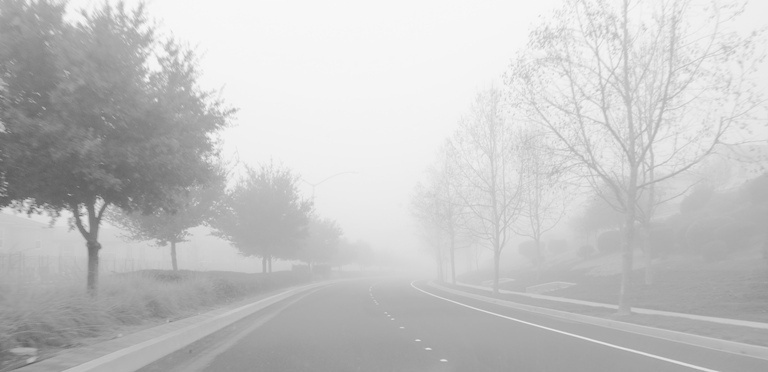


--- 2. Kuantize Edilmiş (6-bit) Görüntü ---


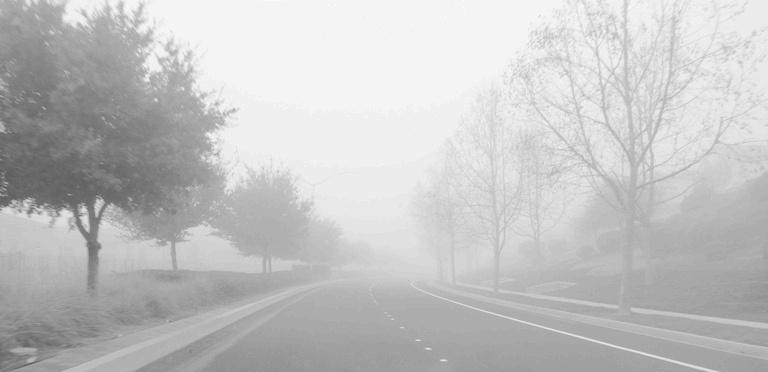


--- 3. Çoklu İş Parçacığı (4 Thread) ile Parlaklık Artırılmış Görüntü ---


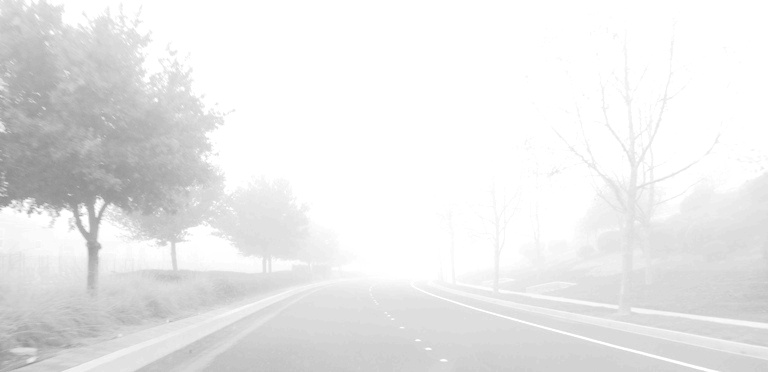

In [52]:
from IPython.display import Image, display

print("--- 1. Orijinal Görüntü ---")
display(Image('1_orijinal.jpg'))

print("\n--- 2. Kuantize Edilmiş (6-bit) Görüntü ---")
display(Image('2_kuantize_6bit.jpg'))

print("\n--- 3. Çoklu İş Parçacığı (4 Thread) ile Parlaklık Artırılmış Görüntü ---")
display(Image('3_parlaklik_arttirilmis.jpg'))